## Name:NIKHIL SINGH
## C-C3-32
##ML EXP6

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report


In [ ]:
df=pd.read_csv("seeds.csv")

In [ ]:
df=df.dropna(axis=1,how="all")

In [ ]:
df=df.loc[:, ~df.columns.str.startswith("Unamed")]

In [ ]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [ ]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3


In [ ]:
df.shape

(210, 8)

In [ ]:
df.columns

Index(['Area', 'Perimeter', 'Compactness', 'Length of kernel',
       'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove',
       'Class (1, 2, 3)'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB


In [ ]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [ ]:
df.isnull().sum()

,0
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1, 2, 3)",0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.nunique()

,0
Area,193
Perimeter,170
Compactness,186
Length of kernel,188
Width of kernel,184
Asymmetry coefficient,207
Length of kernel groove,148
"Class (1, 2, 3)",3


In [ ]:
df['Class (1, 2, 3)'].value_counts()

,count
"Class (1, 2, 3)",
1,70
2,70
3,70


In [ ]:
df.corr(numeric_only=True)

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
Area,1.000000,0.994341,0.608288,0.949985,0.970771,-0.229572,0.863693,-0.346058
Perimeter,0.994341,1.000000,0.529244,0.972422,0.944829,-0.217340,0.890784,-0.327900
Compactness,0.608288,0.529244,1.000000,0.367915,0.761635,-0.331471,0.226825,-0.531007
Length of kernel,0.949985,0.972422,0.367915,1.000000,0.860415,-0.171562,0.932806,-0.257269
Width of kernel,0.970771,0.944829,0.761635,0.860415,1.000000,-0.258037,0.749131,-0.423463
Asymmetry coefficient,-0.229572,-0.217340,-0.331471,-0.171562,-0.258037,1.000000,-0.011079,0.577273
Length of kernel groove,0.863693,0.890784,0.226825,0.932806,0.749131,-0.011079,1.000000,0.024301
"Class (1, 2, 3)",-0.346058,-0.327900,-0.531007,-0.257269,-0.423463,0.577273,0.024301,1.000000


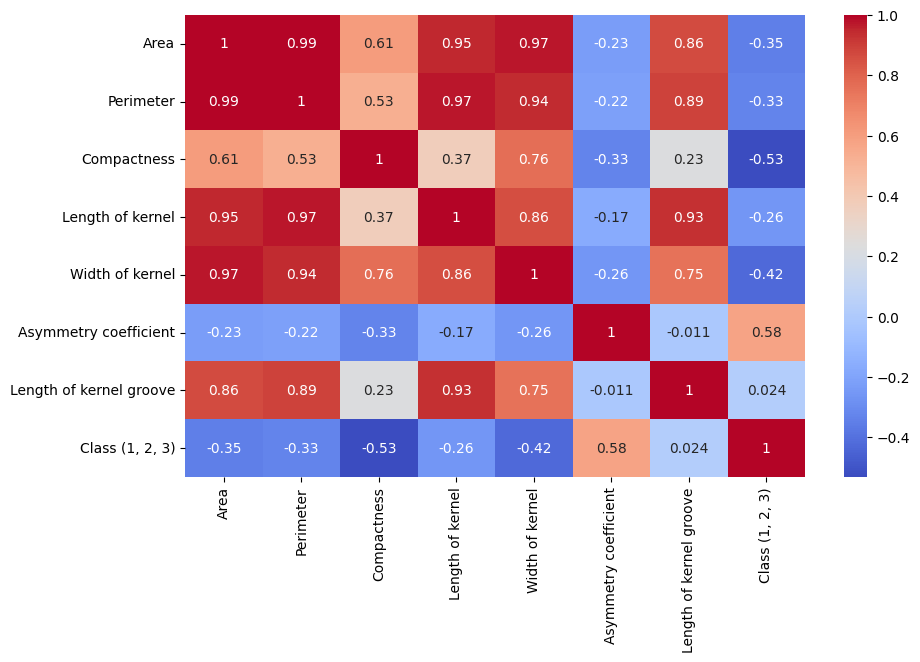

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.show()

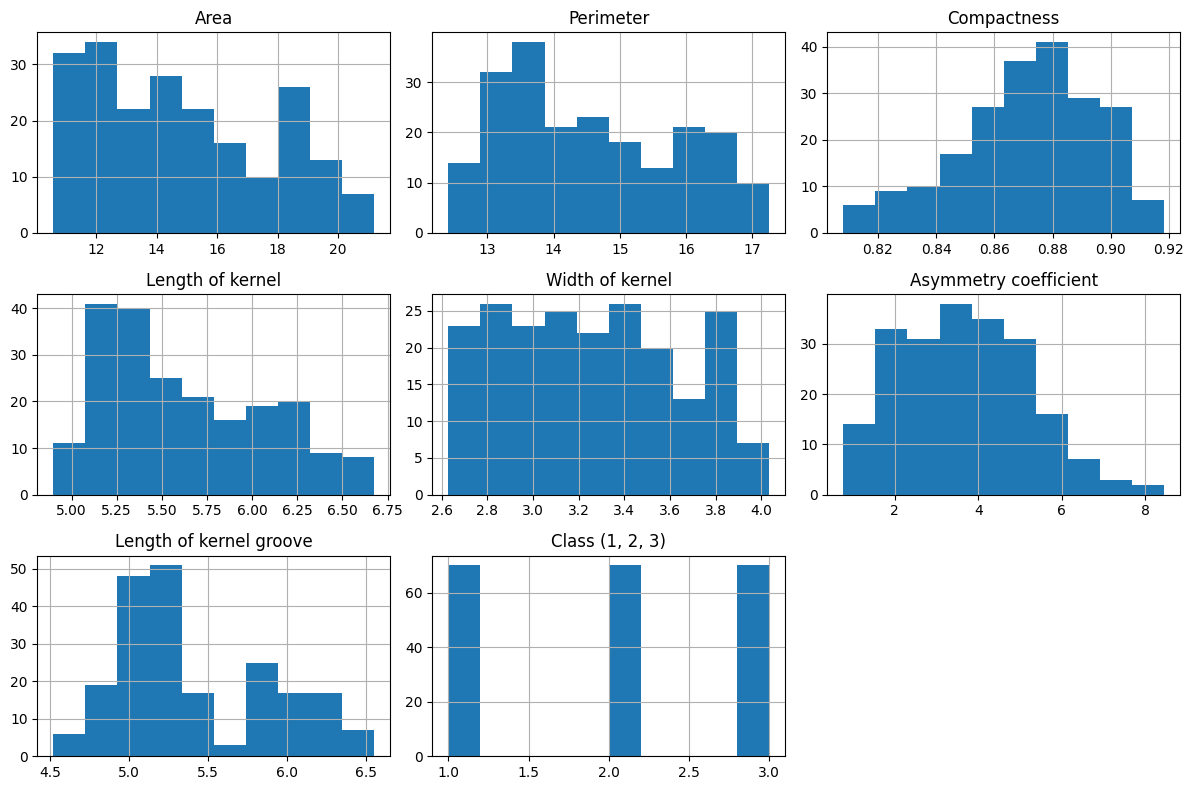

In [ ]:
df.hist(figsize=(12,8))
plt.tight_layout()
plt.show()

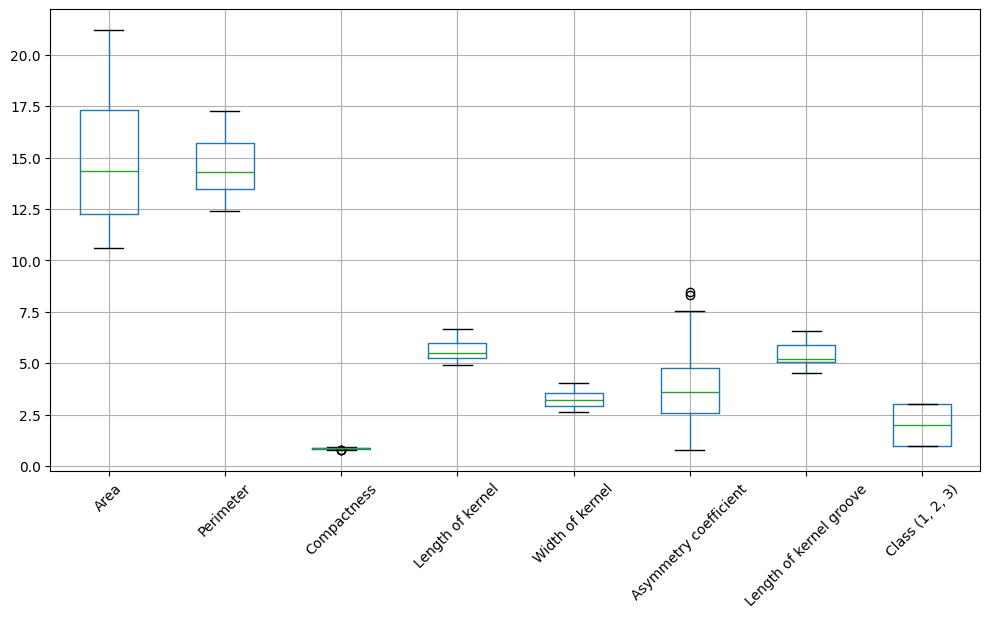

In [ ]:

df.boxplot(figsize=(12,6))
plt.xticks(rotation=45)
plt.show()

In [ ]:
X=df.drop('Class (1, 2, 3)',axis=1)
y_original=df["Class (1, 2, 3)"]
print(X.shape)
print(y_original.shape)

(210, 7)
(210,)


In [ ]:
y=y_original-1
print(sorted(y_original.unique()))
print(sorted(y.unique()))

[np.int64(1), np.int64(2), np.int64(3)]
[np.int64(0), np.int64(1), np.int64(2)]


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [ ]:
scaler.fit_transform(X_test)

array([[-0.52991291, -0.49623599, -0.27871655, -0.28725548, -0.68950684,
        -1.89773913, -0.63786437],
       [-1.17566801, -1.13903806, -1.3157494 , -1.08016108, -1.23712694,
         0.29497821, -0.74893692],
       [ 1.63968755,  1.68929104,  0.22486319,  1.68850928,  1.44414504,
        -0.56016822,  1.60143767],
       [-0.66658066, -0.82898059,  1.01010617, -1.11265721, -0.22454638,
        -0.64523847, -1.08612146],
       [-1.12441761, -1.22222421, -0.18909643, -1.25347378, -1.01239605,
        -0.7264996 , -1.52842824],
       [-1.20300156, -1.07853904, -2.02417513, -0.72920286, -1.46444094,
         1.24979649, -0.3145639 ],
       [-0.31124452, -0.32986369,  0.28460994, -0.45623536, -0.22454638,
        -1.45023154, -0.82629102],
       [-0.8613322 , -0.84410535, -0.63292941, -0.75086695, -0.85999234,
         0.64287742, -0.43555364],
       [ 0.5907626 ,  0.58518396,  0.65162568,  0.64430027,  0.6795434 ,
        -1.19057684,  0.30823578],
       [-0.65633058, -0.7155

In [ ]:
print(X_train[:5])

[[-1.05385596 -1.04083248 -0.88880831 -0.86174582 -1.13018592  1.03548208
  -0.22342116]
 [ 1.52927104  1.5495697   0.46355711  1.60878046  1.46287997 -0.1265987
   1.69031688]
 [-0.86392015 -0.87893234 -0.40975723 -0.96258363 -0.73186961  1.222849
  -0.76198116]
 [-0.17669786 -0.14652697  0.0862514  -0.16046471 -0.29345435 -1.48822186
  -0.23781017]
 [-1.2230715  -1.31837557 -0.4648693  -1.34301718 -1.10612655 -0.21453263
  -0.84831521]]


In [ ]:
model=Sequential([
Input(shape=(7,)),
Dense(64, activation="relu"),
Dense(16, activation="relu"),
Dense(8, activation="softmax")
])

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,688 (6.59 KB)

 Trainable params: 1,688 (6.59 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stop=EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [ ]:
history=model.fit(
    X_train,y_train,
    validation_data=(X_test,y_test),
    batch_size=32,
    validation_split=0.2,
    epochs=100,
    callbacks=[early_stop]
)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.0000e+00 - loss: 2.2924 - val_accuracy: 0.0476 - val_loss: 2.1294
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.0298 - loss: 2.0749 - val_accuracy: 0.2619 - val_loss: 1.9411
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.3690 - loss: 1.9136 - val_accuracy: 0.6190 - val_loss: 1.7855
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5417 - loss: 1.7666 - val_accuracy: 0.7381 - val_loss: 1.6390
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7024 - loss: 1.6228 - val_accuracy: 0.7619 - val_loss: 1.4906
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7738 - loss: 1.4803 - val_accuracy: 0.8333 - val_loss: 1.3405
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8393 - loss: 1.3443 - val_accuracy: 0.8095 - val_loss: 1.1974
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.8512 - loss: 1.2106 - val_accuracy: 0.8571 - val_l

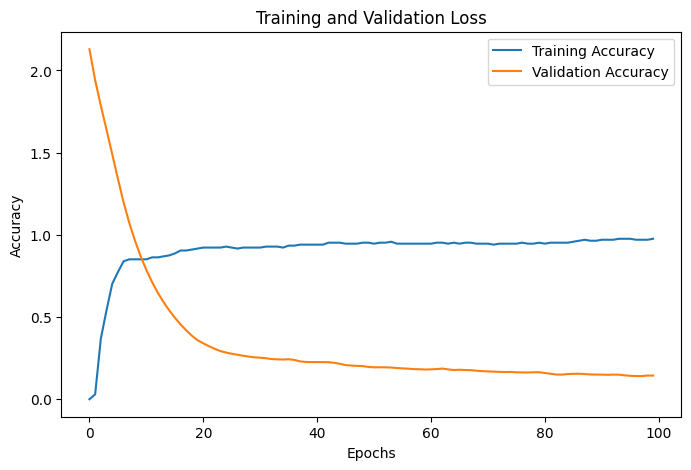

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'],label='Training Accuracy')
plt.plot(history.history['val_loss'],label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

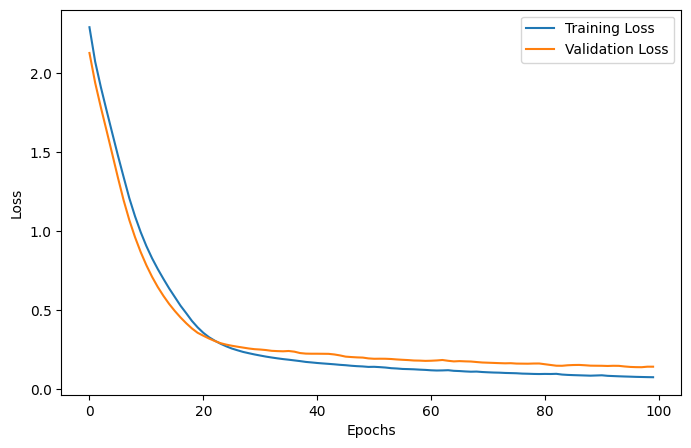

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
test_loss,test_acc=model.evaluate(X_test,y_test)
print(f"Test Accuracy: {test_acc}")
print("test loss:",test_loss)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9524 - loss: 0.1407
Test Accuracy: 0.9523809552192688
test loss: 0.14074283838272095


In [ ]:
y_Prob=model.predict(X_test,verbose=1)
print(y_Prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
[[9.94878948e-01 1.43171026e-04 4.83162422e-03 1.96521505e-05
  5.30736143e-05 2.13577550e-05 4.31842545e-06 4.77905633e-05]
 [1.67225883e-03 1.88041918e-06 9.98310983e-01 1.43470716e-05
  1.08555774e-07 2.16031452e-07 5.86280571e-08 1.51636897e-07]
 [3.75519885e-04 9.99623597e-01 6.62096156e-08 1.19937180e-08
  7.14979365e-07 1.42539065e-07 4.42635306e-09 1.48574015e-08]
 [8.13727140e-01 2.78153503e-03 1.80028901e-01 1.06633676e-03
  8.57798674e-04 5.22998627e-04 1.51142696e-04 8.64129979e-04]
 [5.06756485e-01 7.67491001e-05 4.93062913e-01 6.89712106e-05
  1.29941800e-05 7.05295224e-06 1.53494909e-06 1.32963423e-05]]


In [ ]:
y_pred = np.argmax(y_Prob, axis=1)
y_pred_original = y_pred + 1
y_test_original = y_test + 1
print(y_pred_original[:10])

[1 3 2 1 1 3 1 3 1 3]


In [ ]:
comparison=pd.DataFrame({'Actual':y_test_original,'Predicted':y_pred_original})
print(comparison.head(15))

     Actual  Predicted
30        1          1
172       3          3
84        2          2
199       3          1
60        1          1
155       3          3
45        1          1
182       3          3
9         1          1
196       3          3
136       2          2
187       3          3
207       3          3
126       2          2
15        1          1


In [ ]:
accuracy=accuracy_score(y_test_original,y_pred_original)
print(f"Accuracy: {accuracy}")

Accuracy: 0.9523809523809523


In [ ]:
from sklearn.metrics import precision_score
precision=precision_score(y_test_original,y_pred_original,average='weighted')
print(f"Precision: {precision}")

Precision: 0.9523809523809523


In [ ]:
from sklearn.metrics import recall_score
recall=recall_score(y_test_original,y_pred_original,average='weighted')
print(f"Recall: {recall}")

Recall: 0.9523809523809523


In [ ]:
from sklearn.metrics import f1_score
f1=f1_score(y_test_original,y_pred_original,average='weighted')
print(f"F1 Score: {f1}")


F1 Score: 0.9523809523809523


In [ ]:
print(classification_report(y_test_original,y_pred_original))

              precision    recall  f1-score   support

           1       0.91      0.91      0.91        11
           2       1.00      1.00      1.00        14
           3       0.94      0.94      0.94        17

    accuracy                           0.95        42
   macro avg       0.95      0.95      0.95        42
weighted avg       0.95      0.95      0.95        42



In [ ]:
cm=confusion_matrix(y_test_original,y_pred_original)
print(cm)

[[10  0  1]
 [ 0 14  0]
 [ 1  0 16]]
